<h1> REINFORCE Algorithm (+ baseline)

First, we build the policy network, examine the probability outputs, and then move on to the REINFORCE algorithm.

In this section, we move away from value-based methods and learn how a neural network can directly learn a policy for action selection.

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
import torch.nn as nn
from torch.distributions import Categorical
from pathlib import Path

<h3> Step 1: Setting up the CartPole environment

In our current problem—namely, CartPole-v1—the goal is for the agent to maintain the pole's balance for as long as possible and survive for the maximum number of steps. There is one important point to note: the mathematical objective of the algorithm is to maximize the expected return.

In [3]:
# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Create environment
env = gym.make("CartPole-v1")

# Inspect spaces
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)

# Reset environment
state, info = env.reset(seed=42)

print("Initial state:", state)
print("State shape:", state.shape)

# Extract dimensions
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

print("State dimension:", state_dim)
print("Action dimension:", action_dim)

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
Initial state: [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]
State shape: (4,)
State dimension: 4
Action dimension: 2


<h3> Step 2: Building a Policy Network

In [4]:
class PolicyNetwork(nn.Module):

    def __init__(
        self,
        state_dim,
        action_dim,
        hidden_dim=128
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, action_dim)
        )

    def forward(self, state):
        return self.network(state)


policy_net = PolicyNetwork(
    state_dim=state_dim,
    action_dim=action_dim
)

print(policy_net)

PolicyNetwork(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


The output should represent an architecture consisting of three Linear layers and two ReLU layers; the final layer has two outputs.

Important note: We have intentionally omitted a Softmax layer at the end. Later, we will use `Categorical(logits=...)` to calculate the action distribution, which performs the conversion to probabilities in a numerically stable manner.

<h3> Step 3: Analyzing the network output

In [5]:
# Convert state to a PyTorch tensor
state_tensor = torch.as_tensor(
    state,
    dtype=torch.float32
).unsqueeze(0)

# Get logits and probabilities
with torch.no_grad():

    logits = policy_net(state_tensor)

    probabilities = torch.softmax(
        logits,
        dim=-1
    )

print("Logits:", logits)
print("Logits shape:", logits.shape)

print("Probabilities:", probabilities)
print("Probabilities shape:", probabilities.shape)

print(
    "Sum of probabilities:",
    probabilities.sum(dim=-1).item()
)

Logits: tensor([[ 0.0207, -0.0128]])
Logits shape: torch.Size([1, 2])
Probabilities: tensor([[0.5084, 0.4916]])
Probabilities shape: torch.Size([1, 2])
Sum of probabilities: 0.9999999403953552


The outputs are perfectly correct. The network has not yet been trained, so the probabilities for the two actions are nearly equal—exactly what we would expect given the initial weights.
- Logits: The network's raw output for the two actions.
- Probabilities: The probability for the left action is approximately 0.5084, and for the right action, it is about 0.4916.
- The sum of the probabilities is approximately 1.0. The very slight discrepancy is due to the precision of floating-point calculations.

<h3> Step 4: Action Sampling with Categorical

In DQN, we typically selected the action with the highest Q-value. In Policy Gradient, however, we sample the action from the policy's probability distribution.

In [8]:
# Convert state to tensor
state_tensor = torch.as_tensor(
    state,
    dtype=torch.float32
).unsqueeze(0)

# Get policy logits
logits = policy_net(state_tensor)

# Create action probability distribution
distribution = Categorical(
    logits=logits
)

# Sample an action
action = distribution.sample()

# Log-probability of the selected action
log_prob = distribution.log_prob(action)

print("Sampled action:", action.item())
print("Log probability:", log_prob.item())
print(
    "Probability of sampled action:",
    log_prob.exp().item()
)

Sampled action: 1
Log probability: -0.7100815176963806
Probability of sampled action: 0.49160411953926086


<h3> Step 5: Observing the stochastic behavior of policy

In [9]:
state_tensor = torch.as_tensor(
    state,
    dtype=torch.float32
).unsqueeze(0)

logits = policy_net(state_tensor)

distribution = Categorical(
    logits=logits
)

for i in range(10):
    action = distribution.sample()

    print(
        f"Sample {i + 1}: action = {action.item()}"
    )

Sample 1: action = 1
Sample 2: action = 0
Sample 3: action = 0
Sample 4: action = 1
Sample 5: action = 0
Sample 6: action = 0
Sample 7: action = 1
Sample 8: action = 1
Sample 9: action = 1
Sample 10: action = 1


Both actions 0 and 1 have been sampled, which indicates that the network uses the policy's probability distribution to select an action, rather than always choosing the action with the higher probability.

At this stage, we haven't learned anything yet; we have only implemented the mechanism for selecting actions.

<h3> Step 6: Executing an Episode and Storing Experiences

In the REINFORCE algorithm, the agent executes an episode and then updates its policy based on the rewards it has received.

For each step, we store two main items:
- log_prob: The logarithm of the probability of the action selected by the policy.
- reward: The reward received from the environment after executing that action.

In the CartPole-v1 environment, each step yields a reward of +1; therefore, the total episode reward is equal to the number of steps the agent managed to keep the pole balanced.

In [10]:
def generate_episode(env, policy_net):

    log_probs = []
    rewards = []

    state, info = env.reset()
    terminated = False
    truncated = False

    while not (terminated or truncated):

        # Convert state to tensor
        state_tensor = torch.as_tensor(
            state,
            dtype=torch.float32
        ).unsqueeze(0)

        # Calculate policy logits
        logits = policy_net(state_tensor)

        # Create action distribution
        distribution = Categorical(
            logits=logits
        )

        # Sample action
        action = distribution.sample()

        # Store log-probability
        log_prob = distribution.log_prob(
            action
        )

        # Interact with environment
        next_state, reward, terminated, truncated, info = (
            env.step(action.item())
        )

        log_probs.append(log_prob.squeeze())
        rewards.append(reward)

        state = next_state

    return log_probs, rewards

<h3> Step 7: Trial execution and output review

In [11]:
log_probs, rewards = generate_episode(
    env,
    policy_net
)

print("Episode length:", len(rewards))
print("Total reward:", sum(rewards))
print("Number of log_probs:", len(log_probs))
print("First 5 rewards:", rewards[:5])

print("\nFirst 5 log probabilities:")

for log_prob in log_probs[:5]:
    print(log_prob.item())

Episode length: 32
Total reward: 32.0
Number of log_probs: 32
First 5 rewards: [1.0, 1.0, 1.0, 1.0, 1.0]

First 5 log probabilities:
-0.713506817817688
-0.6724814176559448
-0.6737012267112732
-0.6836594939231873
-0.6953386664390564


The next step is the calculation of returns—that is, determining the return at each step based on the sum of future rewards. This value serves as the basis for deciding which policy decisions to reinforce or weaken.

<h3> Step 8: Calculating the Returns

In REINFORCE, we do not consider only the immediate reward; rather, we calculate the sum of future rewards.
The return from time step $t$ onwards is defined as follows:

$G_t=\sum_{k=0}^{T-t-1}\gamma^k r_{t+k}$

Where:
- $G_t$: The return from the current time step to the end of the episode.
- $r_t$: The reward at the current time step.
- $\gamma$: The discount factor.
- $T$: The length of the episode.

The discount factor determines the importance assigned to future rewards.

We use the following value:

$\gamma=0.99$

For example, if the next three rewards are each equal to one, the return is:

$G_t=1+0.99+0.99^2=2.9701$

Therefore, the initial steps of an episode typically yield a higher return, as they encompass rewards from a greater number of subsequent steps.

In [12]:
def compute_returns(rewards, gamma=0.99):

    returns = []
    G = 0.0

    # Traverse rewards backward
    for reward in reversed(rewards):

        G = reward + gamma * G
        returns.append(G)

    # Restore chronological order
    returns.reverse()

    return returns

Why do we move from the end of an episode to the beginning?
Because we can use the following recursive relationship:

$G_t=r_t+\gamma G_{t+1}$

Consequently, there is no need to re-sum all future rewards for every single step.

<h4> Calculation and review of the output

In [13]:
gamma = 0.99

returns = compute_returns(
    rewards,
    gamma=gamma
)

print("Episode length:", len(rewards))
print("Returns length:", len(returns))

print("\nFirst 5 returns:")
print(returns[:5])

print("\nLast 5 returns:")
print(returns[-5:])

print("\nFirst return:", returns[0])
print("Last return:", returns[-1])

Episode length: 32
Returns length: 32

First 5 returns:
[27.501966404214627, 26.76966303456023, 26.02996266117195, 25.282790566840355, 24.528071279636723]

Last 5 returns:
[4.90099501, 3.9403989999999998, 2.9701, 1.99, 1.0]

First return: 27.501966404214627
Last return: 1.0


<h3> Step 9: Calculating Policy Loss and Updating the Network

Now we arrive at the core of the REINFORCE algorithm: using returns to update the weights of the policy network.
So far, we have run one episode and have two arrays:
- `log_probs`: the logarithms of the probabilities of the selected actions
- `returns`: the discounted return for each step

We now combine these to construct the loss and learn the policy using gradient descent.

By calculating the gradient and executing `optimizer.step()`, the network weights are updated to steer the policy toward selecting actions that have yielded higher returns.

In [14]:
# Convert log probabilities and returns to tensors
log_probs_tensor = torch.stack(log_probs)

returns_tensor = torch.tensor(
    returns,
    dtype=torch.float32
)

# Create optimizer
optimizer = torch.optim.Adam(
    policy_net.parameters(),
    lr=1e-3
)

# Save parameters before the update
weights_before = [
    param.detach().clone()
    for param in policy_net.parameters()
]

# Calculate REINFORCE loss
loss = -(
    log_probs_tensor * returns_tensor
).sum()

# Gradient descent
optimizer.zero_grad()
loss.backward()

# Update policy network
optimizer.step()

# Measure parameter changes
total_change = sum(
    (after.detach() - before).abs().sum().item()
    for before, after in zip(
        weights_before,
        policy_net.parameters()
    )
)

print("Log probabilities shape:", log_probs_tensor.shape)
print("Returns shape:", returns_tensor.shape)
print("Policy loss:", loss.item())
print("Total parameter change:", total_change)
print(
    "Weights updated:",
    total_change > 0
)

Log probabilities shape: torch.Size([32])
Returns shape: torch.Size([32])
Policy loss: 329.9591064453125
Total parameter change: 7.661924095824361
Weights updated: True


If the weights have changed, it means the network has effectively undergone a learning step.

However, a change in weights does not, by itself, imply improved performance. Since REINFORCE relies on a stochastic gradient estimate, the performance in a subsequent episode could turn out to be either better or worse.

At this stage, we use raw returns. Later, by examining variance and incorporating a baseline, we will learn how to make policy updates more stable.

<h3> Step 10: Complete Train on REINFORCE

Since we previously performed a trial update on the network, it is best to re-initialize the network from scratch for the main experiment, ensuring that the training results are not influenced by that prior test.

In [15]:
# Reset random seeds
np.random.seed(42)
torch.manual_seed(42)

# Initialize a fresh policy network
policy_net = PolicyNetwork(
    state_dim=state_dim,
    action_dim=action_dim
)

# Create a fresh optimizer
optimizer = torch.optim.Adam(
    policy_net.parameters(),
    lr=1e-3
)

# Seed the environment
env.reset(seed=42)

print("Policy network reset successfully.")
print("Optimizer initialized.")

Policy network reset successfully.
Optimizer initialized.


<h4> Train Loop

In [16]:
def train_reinforce(
    env,
    policy_net,
    optimizer,
    num_episodes=1000,
    gamma=0.99
):
    episode_rewards = []
    episode_losses = []

    for episode in range(1, num_episodes + 1):

        # Generate a complete episode
        log_probs, rewards = generate_episode(
            env,
            policy_net
        )

        # Calculate discounted returns
        returns = compute_returns(
            rewards,
            gamma
        )

        returns_tensor = torch.tensor(
            returns,
            dtype=torch.float32
        )

        log_probs_tensor = torch.stack(log_probs)

        # Calculate REINFORCE loss
        loss = -(
            log_probs_tensor * returns_tensor
        ).sum()

        # Update policy
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_reward = sum(rewards)

        episode_rewards.append(total_reward)
        episode_losses.append(loss.item())

        if episode % 50 == 0:
            mean_reward = np.mean(
                episode_rewards[-50:]
            )

            mean_loss = np.mean(
                episode_losses[-50:]
            )

            print(
                f"Episode {episode:4d} | "
                f"Mean reward (last 50): "
                f"{mean_reward:.2f} | "
                f"Mean loss (last 50): "
                f"{mean_loss:.2f}"
            )

    return episode_rewards, episode_losses

<h4> Run the Train

An important point is that standard REINFORCE uses the raw return, which may exhibit high variance. We can examine the effect of a baseline later.

In the REINFORCE algorithm, the purpose of a baseline is to reduce the variance of the gradient—thereby making training more stable—without altering the expected value of the policy gradient.

In [17]:
reinforce_rewards, reinforce_losses = train_reinforce(
    env=env,
    policy_net=policy_net,
    optimizer=optimizer,
    num_episodes=1000,
    gamma=0.99
)

Episode   50 | Mean reward (last 50): 35.00 | Mean loss (last 50): 471.57
Episode  100 | Mean reward (last 50): 42.98 | Mean loss (last 50): 650.79
Episode  150 | Mean reward (last 50): 68.24 | Mean loss (last 50): 1372.76
Episode  200 | Mean reward (last 50): 180.54 | Mean loss (last 50): 5834.62
Episode  250 | Mean reward (last 50): 233.56 | Mean loss (last 50): 8067.53
Episode  300 | Mean reward (last 50): 125.92 | Mean loss (last 50): 3017.93
Episode  350 | Mean reward (last 50): 153.80 | Mean loss (last 50): 3970.24
Episode  400 | Mean reward (last 50): 257.18 | Mean loss (last 50): 8322.48
Episode  450 | Mean reward (last 50): 220.76 | Mean loss (last 50): 7019.16
Episode  500 | Mean reward (last 50): 333.82 | Mean loss (last 50): 12232.04
Episode  550 | Mean reward (last 50): 308.82 | Mean loss (last 50): 10909.63
Episode  600 | Mean reward (last 50): 250.58 | Mean loss (last 50): 8071.18
Episode  650 | Mean reward (last 50): 253.90 | Mean loss (last 50): 7938.88
Episode  700 | 

The REINFORCE algorithm has indeed learned, but it still lacks the necessary stability. The most significant evidence for this is the spike in performance—reaching near the environment's upper limit—at episode 900, followed by a sharp drop by episode 1000.

#### A) Initial Learning: Episodes 1 to 200
The average reward has increased from 35.00 to 180.54. This is a positive sign: the policy has succeeded in increasing the probability of selecting appropriate actions and maintaining balance for longer periods.

##### B) Progress with Fluctuations: Episodes 200 to 850
Performance has fluctuated, improving and declining at various points; for instance, the average dropped from 333.82 at episode 500 to 250.58 at episode 600, before rising again to 324.36 at episode 700.</br>
This behavior is consistent with the nature of the REINFORCE algorithm. Since raw returns are used, the gradient estimate can exhibit high variance, and policy updates may occasionally lead to a drop in performance.

#### C) Performance Surge: Episode 900
The average over the last 50 episodes reached 497.92, indicating that the agent achieved near-optimal performance for the environment during this interval.</br>
This result demonstrates that the network possesses the capacity to learn an effective policy.

#### D) Sharp Decline: Episode 1000
The average over the final 50 episodes plummeted to 79.76. </br> Consequently, we cannot conclude that the policy achieved a high level of performance by the end of the training process.</br>
This decline is likely due to the volatility of the policy updates; however, to definitively identify the cause, one would need to examine the plots and the specific behavior of the episodes.

#### Why has the loss become so large?
The loss values ​​have increased from 471.57 at the beginning to 18,904.94 by episode 900. This does not necessarily mean that the training is getting worse.
Our loss function is defined as follows:

$L(\theta)=-\sum_{t=0}^{T-1}G_t\log\pi_\theta(a_t\mid s_t)$

As episodes become longer, the number of terms in this summation increases, and the returns ($G_t$) for the initial steps also tend to be larger; consequently, the loss value can grow significantly.</br>
Therefore, in the REINFORCE algorithm, we do not use the raw loss value alone as a metric for policy quality. Instead, our primary criteria are the evaluation rewards and the stability of performance over time.

<h3> Step 11: Charts

<h3> Step 11.1: Learning Curve Chart

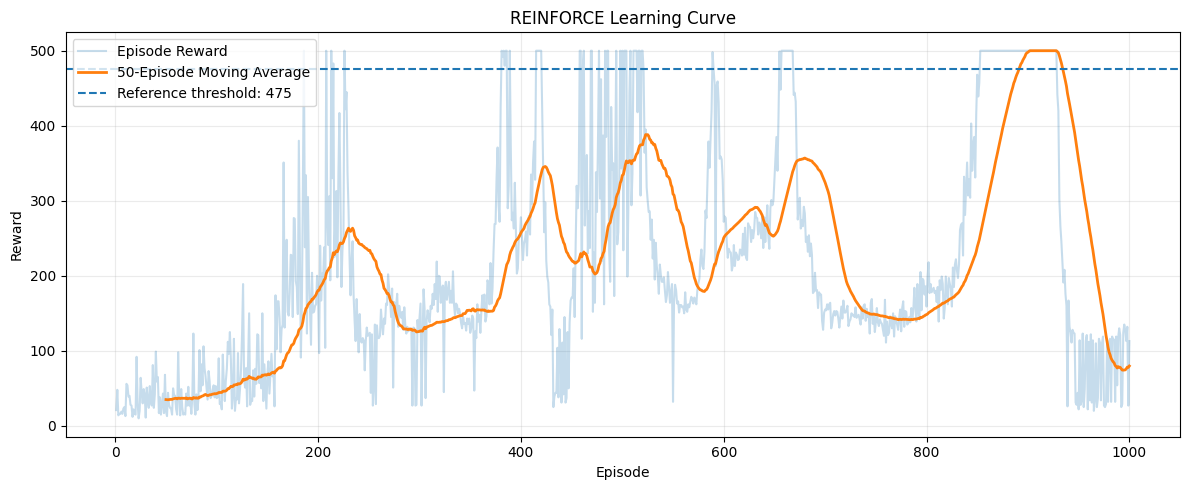

In [20]:
rewards = np.asarray(reinforce_rewards, dtype=float)
losses = np.asarray(reinforce_losses, dtype=float)

window = 50

moving_avg = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    np.arange(1, len(rewards) + 1),
    rewards,
    alpha=0.25,
    label="Episode Reward"
)

ax.plot(
    np.arange(window, len(rewards) + 1),
    moving_avg,
    linewidth=2,
    label="50-Episode Moving Average"
)

ax.axhline(
    475,
    linestyle="--",
    label="Reference threshold: 475"
)

ax.set_xlabel("Episode")
ax.set_ylabel("Reward")
ax.set_title("REINFORCE Learning Curve")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

#### Learning Curve Chart Analysis

- Up to approximately episode 200, the learning process is promising, with the average reward showing an upward trend.
- Between episodes 400 and 850, the agent achieves better performance on several occasions but fails to sustain it.
- Around episode 900, the moving average reaches 500, indicating that the agent has attained near-optimal performance within the environment during this period.
- Subsequently, performance drops sharply, with the average over the final 50 episodes falling to 79.76.

This decline demonstrates that a learned policy can undergo significant changes due to subsequent updates. Therefore, the best performance observed is not necessarily the agent's final performance.

<h3> Step 11.2: Loss Chart

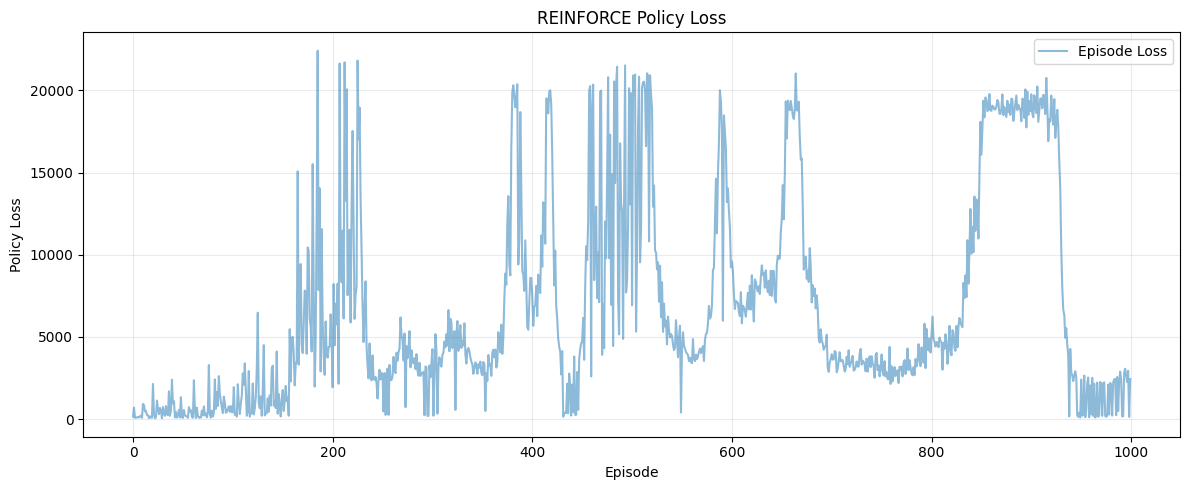

In [21]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(losses, alpha=0.5, label="Episode Loss")

ax.set_xlabel("Episode")
ax.set_ylabel("Policy Loss")
ax.set_title("REINFORCE Policy Loss")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

#### Loss Chart Analysis

The loss value rises to approximately 22,000 before dropping. This behavior does not necessarily indicate that the learning process is getting worse or better.
Since we use a summation, both the episode length and the magnitude of the returns influence the loss value. For this reason, the loss should not be considered, on its own, as a metric for the quality of the policy.

The fluctuations are extreme, and the graphs show precisely one of the main weaknesses of conventional REINFORCE: the high variance of the gradient and the instability of the policy during training.

<h3> Step 12: REINFORCE with Baseline

<h3> Step 12.1: Saving states for baseline training

In [22]:
def generate_episode_with_states(env, policy_net):

    states = []
    log_probs = []
    rewards = []

    state, info = env.reset()

    terminated = False
    truncated = False

    while not (terminated or truncated):

        # Save the current state
        states.append(state.copy())

        # Convert state to tensor
        state_tensor = torch.as_tensor(
            state,
            dtype=torch.float32
        ).unsqueeze(0)

        # Policy network
        logits = policy_net(state_tensor)

        distribution = Categorical(
            logits=logits
        )

        # Sample action
        action = distribution.sample()

        log_prob = distribution.log_prob(action)

        # Interact with environment
        next_state, reward, terminated, truncated, info = (
            env.step(action.item())
        )

        log_probs.append(log_prob.squeeze())
        rewards.append(reward)

        state = next_state

    return states, log_probs, rewards

In [23]:
states, log_probs, rewards = generate_episode_with_states(
    env,
    policy_net
)

print("States shape:", np.asarray(states).shape)
print("Number of log_probs:", len(log_probs))
print("Number of rewards:", len(rewards))
print("Episode reward:", sum(rewards))

States shape: (123, 4)
Number of log_probs: 123
Number of rewards: 123
Episode reward: 123.0


<h3> Step 12.2: Building the Value Network

In standard REINFORCE, we used the raw return to update the policy:

$G_t$

However, this value alone does not indicate how much better or worse the performance of the chosen action was compared to expectations.
To address this, we construct a value network to estimate the following function:

$V_\phi(s)=\mathbb{E}[G_t\mid S_t=s]$

In other words, the value of a state is the expected return from that state onwards, given the policy currently being executed by the agent.
We then calculate the advantage:

$A_t=G_t-V_\phi(s_t)$

For instance, if the actual return is 100 and the value network estimates the value of that state to be 70, we have:

$A_t=100-70=30$

This means the outcome was better than expected. This comparison helps reduce the variance of the policy gradient.

In [24]:
class ValueNetwork(nn.Module):

    def __init__(
        self,
        state_dim,
        hidden_dim=128
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, 1)
        )

    def forward(self, state):
        return self.network(state).squeeze(-1)

Now, for testing purposes, we initialize both networks from scratch. This is important because we want to evaluate the baseline version independently of the previous REINFORCE training.

In [25]:
# Reset random seeds
np.random.seed(42)
torch.manual_seed(42)

# Fresh policy network
policy_net = PolicyNetwork(
    state_dim=state_dim,
    action_dim=action_dim
)

# Fresh value network
value_net = ValueNetwork(
    state_dim=state_dim
)

# Separate optimizers
policy_optimizer = torch.optim.Adam(
    policy_net.parameters(),
    lr=1e-3
)

value_optimizer = torch.optim.Adam(
    value_net.parameters(),
    lr=1e-3
)

print("Policy network created:", isinstance(
    policy_net, PolicyNetwork
))

print("Value network created:", isinstance(
    value_net, ValueNetwork
))

print(value_net)

Policy network created: True
Value network created: True
ValueNetwork(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)


<h3> Step 12.3: Analyzing the output of the value network

Now, we will examine the network estimating a single number for a given situation.

In [26]:
test_state, info = env.reset(seed=123)

test_state_tensor = torch.as_tensor(
    test_state,
    dtype=torch.float32
).unsqueeze(0)

with torch.no_grad():
    estimated_value = value_net(
        test_state_tensor
    )

print("State shape:", test_state_tensor.shape)
print("Value output:", estimated_value)
print("Value output shape:", estimated_value.shape)

State shape: torch.Size([1, 4])
Value output: tensor([0.0780])
Value output shape: torch.Size([1])


The 'Value output' represents the Value Network's initial estimate; since the Value Network has not yet been trained, there is currently no reason to expect this figure to correspond to the actual return from the environment.

An important point is that the output of the ValueNetwork is not a probability, but rather an estimate of the expected return from a given state. Therefore, unlike the output of the PolicyNetwork, it is not constrained to be between zero and one.

Of course, the network has not yet been trained; therefore, its initial output might even be negative and, for the time being, lack any reliable meaning.

<h4> The PolicyNetwork indicates the likelihood of various actions, while the ValueNetwork estimates the expected return from the current state. The latter is not intended to generate probabilities; rather, it establishes a metric for comparing actual performance against expected performance.

<h3> Step 12.4: Calculating Return, Value, and Advantage

At this stage, we have three values:
- Return: The actual return calculated from future rewards.
- Value: The network's estimate of the expected return for the current state.
- Advantage: The difference between the actual return and the estimated return.

$A_t=G_t-V_\phi(s_t)$

<h4> Launching a new episode

Since we have initialized the policy network from the start, we generate a new episode using this same network, ensuring that the states, rewards, and action probabilities all correspond to a single policy.

In [27]:
states, log_probs, rewards = generate_episode_with_states(
    env,
    policy_net
)

returns = compute_returns(
    rewards,
    gamma=0.99
)

# Convert data to tensors
states_tensor = torch.as_tensor(
    np.asarray(states),
    dtype=torch.float32
)

returns_tensor = torch.tensor(
    returns,
    dtype=torch.float32
)

# Estimate state values
values = value_net(states_tensor)

# Calculate advantages
advantages = returns_tensor - values.detach()

print("States shape:", states_tensor.shape)
print("Returns shape:", returns_tensor.shape)
print("Values shape:", values.shape)
print("Advantages shape:", advantages.shape)

print("\nFirst 5 returns:")
print(returns_tensor[:5].detach().numpy())

print("\nFirst 5 estimated values:")
print(values[:5].detach().numpy())

print("\nFirst 5 advantages:")
print(advantages[:5].detach().numpy())

States shape: torch.Size([14, 4])
Returns shape: torch.Size([14])
Values shape: torch.Size([14])
Advantages shape: torch.Size([14])

First 5 returns:
[13.125419 12.247898 11.361513 10.466174  9.561792]

First 5 estimated values:
[0.07958382 0.07356934 0.08016312 0.08313623 0.08081496]

First 5 advantages:
[13.045835 12.174329 11.28135  10.383038  9.480977]


`values.detach()` ensures that, when calculating the policy loss, gradients do not flow into the value network via the advantage path.

We expect the shape of all four primary arrays to correspond to the number of steps in the episode; for instance, if an episode consists of 80 steps, the shape of `states_tensor` will be `(80, 4)`, while the shape of the other three arrays will be `(80,)`.

<h3> Step 12.5: Training the Value Network

The value network must learn to estimate the return. For this, we use the mean square error function:

$L_V(\phi)=
\frac{1}{T}\sum_{t=0}^{T-1}
\left(V_\phi(s_t)-G_t\right)^2$

If the network estimates are far from the actual returns, the loss will be larger.

In [28]:
# Value predictions before training
value_predictions = value_net(states_tensor)

value_loss_before = nn.functional.mse_loss(
    value_predictions,
    returns_tensor
)

# Update the value network
value_optimizer.zero_grad()

value_loss_before.backward()

value_optimizer.step()

# Evaluate the updated network
with torch.no_grad():
    updated_values = value_net(states_tensor)

    value_loss_after = nn.functional.mse_loss(
        updated_values,
        returns_tensor
    )

print("Value loss before update:", value_loss_before.item())
print("Value loss after update:", value_loss_after.item())

Value loss before update: 64.61970520019531
Value loss after update: 63.720985412597656


Value loss before update: Network estimation error before the update.

Value loss after update: Estimation error after one optimization step.

<h3> Step 12.6: Complete Train on REINFORCE with Baseline

In this case, we have two networks:
- Policy Network: Learns which actions to select.
- Value Network: Learns to estimate the expected return for each state.
In each episode, the policy is updated using the Advantage:

$A_t=G_t-V_\phi(s_t)$

And the value network is trained by minimizing the squared error:

$L_V=\frac{1}{T}\sum_t(V_\phi(s_t)-G_t)^2$

<h4> Network Initialization

Since we trained the value network experimentally in the previous stage, we re-initialize both networks from scratch so that the main experiment remains independent.

In [29]:
# Reset random seeds
np.random.seed(42)
torch.manual_seed(42)

# Create fresh networks
policy_net = PolicyNetwork(
    state_dim=state_dim,
    action_dim=action_dim
)

value_net = ValueNetwork(
    state_dim=state_dim
)

# Separate optimizers
policy_optimizer = torch.optim.Adam(
    policy_net.parameters(),
    lr=1e-3
)

value_optimizer = torch.optim.Adam(
    value_net.parameters(),
    lr=1e-3
)

env.reset(seed=42)

print("Policy network initialized.")
print("Value network initialized.")

Policy network initialized.
Value network initialized.


<h4> Train Loop Implementation

In [30]:
def train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=1000,
    gamma=0.99
):
    episode_rewards = []
    policy_losses = []
    value_losses = []

    for episode in range(1, num_episodes + 1):

        # Generate a complete episode
        states, log_probs, rewards = (
            generate_episode_with_states(
                env,
                policy_net
            )
        )

        # Convert episode data to tensors
        states_tensor = torch.as_tensor(
            np.asarray(states),
            dtype=torch.float32
        )

        returns_tensor = torch.tensor(
            compute_returns(rewards, gamma),
            dtype=torch.float32
        )

        log_probs_tensor = torch.stack(log_probs)

        # Estimate state values
        values = value_net(states_tensor)

        # Calculate advantages
        advantages = returns_tensor - values.detach()

        # Policy loss
        policy_loss = -(
            log_probs_tensor * advantages
        ).sum()

        # Value loss
        value_loss = nn.functional.mse_loss(
            values,
            returns_tensor
        )

        # Update policy network
        policy_optimizer.zero_grad()
        policy_loss.backward()
        policy_optimizer.step()

        # Update value network
        value_optimizer.zero_grad()
        value_loss.backward()
        value_optimizer.step()

        # Record metrics
        episode_rewards.append(sum(rewards))
        policy_losses.append(policy_loss.item())
        value_losses.append(value_loss.item())

        # Print progress
        if episode % 50 == 0:

            mean_reward = np.mean(
                episode_rewards[-50:]
            )

            mean_policy_loss = np.mean(
                policy_losses[-50:]
            )

            mean_value_loss = np.mean(
                value_losses[-50:]
            )

            print(
                f"Episode {episode:4d} | "
                f"Mean reward: {mean_reward:.2f} | "
                f"Policy loss: {mean_policy_loss:.2f} | "
                f"Value loss: {mean_value_loss:.2f}"
            )

    return (
        episode_rewards,
        policy_losses,
        value_losses
    )

<h4> Run the Train

What should you look for when examining the outputs?

- Mean reward: Has performance become more stable compared to the previous REINFORCE implementation?
- Policy loss: Do not directly compare its raw value with the loss from the previous policy network; changes in the Advantage affect its scale.
- Value loss: Is the value network becoming better at estimating returns throughout the training process?
- Reward fluctuations: Have severe drops—such as the performance 
collapse observed after episode 900—been reduced?

Important note: A baseline is typically used to reduce the variance of the gradient estimate; however, it does not guarantee that the reward will increase in every single run.

In [31]:
(
    baseline_rewards,
    baseline_policy_losses,
    baseline_value_losses
) = train_reinforce_baseline(
    env=env,
    policy_net=policy_net,
    value_net=value_net,
    policy_optimizer=policy_optimizer,
    value_optimizer=value_optimizer,
    num_episodes=1000,
    gamma=0.99
)

Episode   50 | Mean reward: 26.46 | Policy loss: 228.07 | Value loss: 185.33
Episode  100 | Mean reward: 56.96 | Policy loss: 550.47 | Value loss: 380.47
Episode  150 | Mean reward: 140.18 | Policy loss: 1002.80 | Value loss: 707.01
Episode  200 | Mean reward: 149.84 | Policy loss: 779.53 | Value loss: 717.20
Episode  250 | Mean reward: 257.60 | Policy loss: 1662.70 | Value loss: 801.67
Episode  300 | Mean reward: 261.54 | Policy loss: 1189.03 | Value loss: 367.62
Episode  350 | Mean reward: 459.94 | Policy loss: 293.18 | Value loss: 383.19
Episode  400 | Mean reward: 419.82 | Policy loss: -88.98 | Value loss: 625.44
Episode  450 | Mean reward: 479.26 | Policy loss: 168.06 | Value loss: 553.93
Episode  500 | Mean reward: 467.22 | Policy loss: 108.66 | Value loss: 482.04
Episode  550 | Mean reward: 492.86 | Policy loss: 369.78 | Value loss: 472.02
Episode  600 | Mean reward: 476.18 | Policy loss: 100.14 | Value loss: 391.29
Episode  650 | Mean reward: 495.58 | Policy loss: -235.11 | Val

#### We observe three significant results:

- Faster learning: The baseline version reached an average score above 450 by around episode 350; the previous version exhibited high volatility throughout much of the training process.
- Better recovery toward the end: Following a sharp drop around episode 900, the baseline version recovered to an average of nearly 500.
- Persistent instability: The decline from 497.58 to 270.72 indicates that the baseline approach alone does not prevent drastic policy shifts.

While these results are promising, given the stochastic nature of the runs, further comparisons are required to draw definitive conclusions regarding the algorithm's superiority.

#### Why is Policy Loss sometimes negative?

For example, in episode 650, the value of Loss is -235.11. This is not an error in itself.
Our formula is as follows:

$L_{\text{policy}}=-\sum_t
\log\pi_\theta(a_t\mid s_t)A_t$

When Advantage is negative, its product in log_prob becomes negative, and after applying the negative sign, the final Loss may become negative.

Therefore, Policy Loss becoming negative is normal and does not indicate the deterioration of education.

<h3> Step 12.7: Direct comparison of two charts

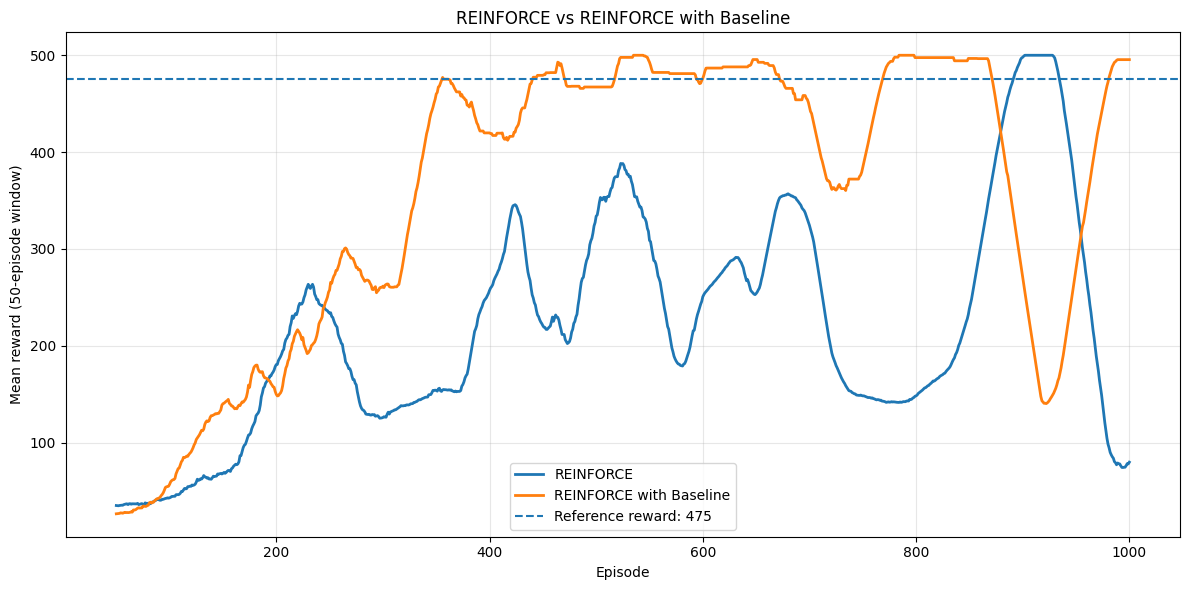

In [32]:
window = 50

reinforce_array = np.asarray(
    reinforce_rewards,
    dtype=float
)

baseline_array = np.asarray(
    baseline_rewards,
    dtype=float
)

def moving_average(rewards, window=50):
    return np.convolve(
        rewards,
        np.ones(window) / window,
        mode="valid"
    )

reinforce_ma = moving_average(
    reinforce_array, window
)

baseline_ma = moving_average(
    baseline_array, window
)

episodes = np.arange(
    window,
    len(reinforce_array) + 1
)

plt.figure(figsize=(12, 6))

plt.plot(
    episodes,
    reinforce_ma,
    label="REINFORCE",
    linewidth=2
)

plt.plot(
    episodes,
    baseline_ma,
    label="REINFORCE with Baseline",
    linewidth=2
)

plt.axhline(
    475,
    linestyle="--",
    label="Reference reward: 475"
)

plt.xlabel("Episode")
plt.ylabel("Mean reward (50-episode window)")
plt.title("REINFORCE vs REINFORCE with Baseline")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In this experiment, REINFORCE with Baseline reached high performance more quickly and performed significantly better than standard REINFORCE by the end of training; however, it still exhibits sharp drops in performance.

- Learning Speed: The Baseline version reached an average above 450 around episode 350; the standard version achieved this level of performance later.
- Stability: The Baseline version remained near 500 for an extended period, though it experienced significant drops around episodes 700 and 900.
- Recovery: By the end, the Baseline version returned to an average of 495.48, whereas the standard version concluded with an average of 79.76.
- Best Performance: Both reached a moving average of 500; therefore, the primary difference lies in the speed at which high performance was attained and the quality of the final window, rather than in the peak value observed.

In [33]:
def summarize_learning(rewards, name, window=50):
    rewards = np.asarray(rewards, dtype=float)
    ma = moving_average(rewards, window)

    best_index = int(np.argmax(ma))

    print(f"\n{name}")
    print("-" * len(name))
    print(f"First 50 mean: {rewards[:50].mean():.2f}")
    print(f"Last 50 mean:  {rewards[-50:].mean():.2f}")
    print(f"Best moving average: {ma[best_index]:.2f}")
    print(f"Best window ends at episode: {best_index + window}")

summarize_learning(
    reinforce_array,
    "REINFORCE"
)

summarize_learning(
    baseline_array,
    "REINFORCE with Baseline"
)


REINFORCE
---------
First 50 mean: 35.00
Last 50 mean:  79.76
Best moving average: 500.00
Best window ends at episode: 902

REINFORCE with Baseline
-----------------------
First 50 mean: 26.46
Last 50 mean:  495.48
Best moving average: 500.00
Best window ends at episode: 535


<h3> Step 12.8: Independent Policy Network Evaluation

Currently, the `policy_net` variable corresponds to the trained REINFORCE with Baseline model. Since we replaced the previous network during the re-initialization step, the weights of the standard REINFORCE model are no longer present in this variable. While we do have the history of its rewards, evaluating both models directly would require us to either store the weights of the standard model separately or retrain it.

For now, we will evaluate the Baseline model.
We will examine two approaches:
- Greedy: The action with the highest probability is always selected.
- Stochastic: The action is sampled from the policy's probability distribution—the same method used during training.

In [34]:
def evaluate_policy(
    policy_net,
    episodes=100,
    seed_start=20_000,
    deterministic=True
):
    eval_env = gym.make("CartPole-v1")
    rewards = []

    was_training = policy_net.training
    policy_net.eval()

    with torch.no_grad():
        for i in range(episodes):

            state, info = eval_env.reset(
                seed=seed_start + i
            )

            terminated = False
            truncated = False
            total_reward = 0

            while not (terminated or truncated):

                state_tensor = torch.as_tensor(
                    state,
                    dtype=torch.float32
                ).unsqueeze(0)

                logits = policy_net(state_tensor)

                if deterministic:
                    action = torch.argmax(
                        logits,
                        dim=-1
                    ).item()
                else:
                    distribution = Categorical(
                        logits=logits
                    )
                    action = distribution.sample().item()

                state, reward, terminated, truncated, info = (
                    eval_env.step(action)
                )

                total_reward += reward

            rewards.append(total_reward)

    eval_env.close()
    policy_net.train(was_training)

    return np.asarray(rewards, dtype=float)

<h4> Run the Evaluation

This code performs only evaluation; the network weights are not updated during evaluation.

In [35]:
# Deterministic evaluation
baseline_greedy_rewards = evaluate_policy(
    policy_net,
    episodes=100,
    deterministic=True
)

# Stochastic evaluation
baseline_stochastic_rewards = evaluate_policy(
    policy_net,
    episodes=100,
    deterministic=False
)


def print_evaluation(name, rewards):

    print(f"\n{name}")
    print("-" * len(name))
    print("Episodes:", len(rewards))
    print(f"Mean reward: {rewards.mean():.2f}")
    print(f"Median reward: {np.median(rewards):.2f}")
    print(f"Std reward: {rewards.std():.2f}")
    print(f"Minimum reward: {rewards.min():.0f}")
    print(f"Maximum reward: {rewards.max():.0f}")
    print("Episodes reaching 500:", np.sum(rewards == 500))
    print("Episodes reaching at least 475:", np.sum(rewards >= 475))


print_evaluation(
    "Baseline - Greedy Evaluation",
    baseline_greedy_rewards
)

print_evaluation(
    "Baseline - Stochastic Evaluation",
    baseline_stochastic_rewards
)


Baseline - Greedy Evaluation
----------------------------
Episodes: 100
Mean reward: 500.00
Median reward: 500.00
Std reward: 0.00
Minimum reward: 500
Maximum reward: 500
Episodes reaching 500: 100
Episodes reaching at least 475: 100

Baseline - Stochastic Evaluation
--------------------------------
Episodes: 100
Mean reward: 500.00
Median reward: 500.00
Std reward: 0.00
Minimum reward: 500
Maximum reward: 500
Episodes reaching 500: 100
Episodes reaching at least 475: 100


<h4> Saving the Results

Since this model has yielded very good results, it is best to save its weights and evaluation results so that we can use them later in the project.

In [37]:
# Create results directory
results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

# Save trained networks and metadata
checkpoint_path = results_dir / "reinforce_baseline_cartpole.pth"

torch.save(
    {
        "algorithm": "REINFORCE with Baseline",
        "policy_state_dict": policy_net.state_dict(),
        "value_state_dict": value_net.state_dict(),
        "state_dim": state_dim,
        "action_dim": action_dim,
        "hidden_dim": 128,
        "gamma": 0.99,
        "training_episodes": 1000,
    },
    checkpoint_path
)

# Save training and evaluation results
metrics_path = results_dir / "reinforce_baseline_results.npz"

np.savez(
    metrics_path,
    training_rewards=np.asarray(baseline_rewards),
    policy_losses=np.asarray(baseline_policy_losses),
    value_losses=np.asarray(baseline_value_losses),
    greedy_eval_rewards=baseline_greedy_rewards,
    stochastic_eval_rewards=baseline_stochastic_rewards,
    reinforce_training_rewards=np.asarray(reinforce_rewards),
    reinforce_training_losses=np.asarray(reinforce_losses),
)

print("Model saved:", checkpoint_path)
print("Results saved:", metrics_path)

Model saved: results\reinforce_baseline_cartpole.pth
Results saved: results\reinforce_baseline_results.npz


We have two files:
- results/reinforce_baseline_cartpole.pth — the final weights of the policy network and the value network.
- results/reinforce_baseline_results.npz — the training and evaluation results for both versions.